# Compare AUC-ROC scores of different models by manually computing true positive and false positive rates at various thresholds, plotting ROC curves without using built-in functions, and analyzing trade-offs in model performance.

Training rows: 734
Testing rows: 184


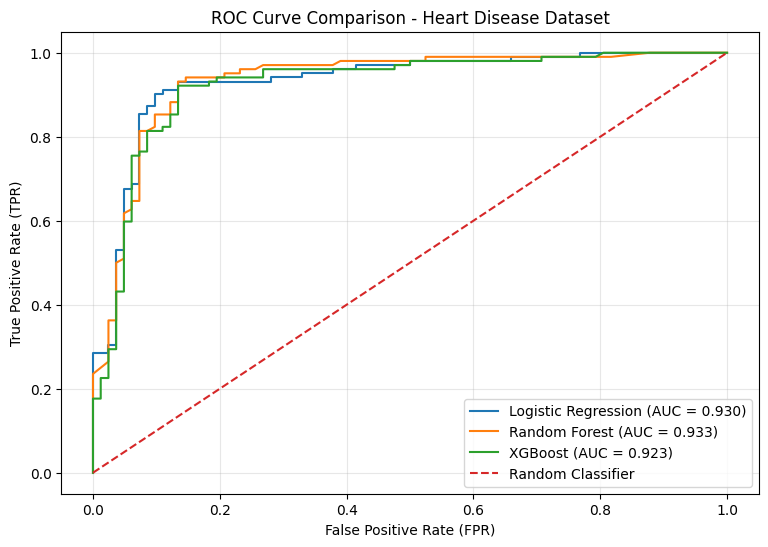


Model Comparison:
              Model    AUC  TPR at 0.5  FPR at 0.5  Specificity at 0.5
      Random Forest 0.9332      0.9314      0.1341              0.8659
Logistic Regression 0.9304      0.9314      0.1707              0.8293
            XGBoost 0.9229      0.9216      0.1829              0.8171

Best Model based on AUC:
Random Forest
Best AUC: 0.9332


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier


# 1. Load dataset
df = pd.read_csv("heart.csv")

X = df.drop("HeartDisease", axis=1)
y = LabelEncoder().fit_transform(df["HeartDisease"])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


# 2. Preprocessing
def create_preprocessor():
    numerical_cols = X.select_dtypes(
        include=["number"]
    ).columns

    categorical_cols = X.select_dtypes(
        include=["object", "str", "category", "bool"]
    ).columns

    numerical_process = SimpleImputer(strategy="median")

    categorical_process = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer([
        ("num", numerical_process, numerical_cols),
        ("cat", categorical_process, categorical_cols)
    ])


# 3. Define models
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", LogisticRegression(max_iter=2000))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", XGBClassifier(
            n_estimators=100,
            max_depth=2,
            learning_rate=0.03,
            subsample=0.7,
            colsample_bytree=0.7,
            min_child_weight=5,
            gamma=0,
            reg_alpha=0.01,
            reg_lambda=5,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1,
            verbosity=0
        ))
    ])
}


# 4. Manually calculate ROC points and AUC
def manual_roc_auc(y_true, scores):
    positives = sum(value == 1 for value in y_true)
    negatives = sum(value == 0 for value in y_true)

    # Thresholds from above maximum to below minimum
    thresholds = (
        [float(max(scores)) + 1]
        + sorted(set(float(s) for s in scores), reverse=True)
        + [float(min(scores)) - 1]
    )

    tpr_values = []
    fpr_values = []

    for threshold in thresholds:
        tp = 0
        fp = 0

        # Count true positives and false positives manually
        for actual, score in zip(y_true, scores):
            predicted_positive = score >= threshold

            if predicted_positive and actual == 1:
                tp += 1
            elif predicted_positive and actual == 0:
                fp += 1

        tpr = tp / positives if positives else 0
        fpr = fp / negatives if negatives else 0

        tpr_values.append(tpr)
        fpr_values.append(fpr)

    # Calculate AUC using the trapezoidal formula
    auc = 0.0

    for i in range(1, len(fpr_values)):
        width = fpr_values[i] - fpr_values[i - 1]
        height = (tpr_values[i] + tpr_values[i - 1]) / 2
        auc += width * height

    return fpr_values, tpr_values, auc


# 5. Calculate TPR and FPR at threshold 0.5
def calculate_rates_at_05(y_true, scores):
    tp = 0
    fp = 0
    positives = sum(value == 1 for value in y_true)
    negatives = sum(value == 0 for value in y_true)

    for actual, score in zip(y_true, scores):
        predicted_positive = score >= 0.5

        if predicted_positive and actual == 1:
            tp += 1
        elif predicted_positive and actual == 0:
            fp += 1

    tpr = tp / positives if positives else 0
    fpr = fp / negatives if negatives else 0

    return tpr, fpr


# 6. Train, evaluate and plot ROC curves
results = []

plt.figure(figsize=(9, 6))

for name, model in models.items():
    model.fit(X_train, y_train)

    # Probability of positive class
    scores = model.predict_proba(X_test)[:, 1]

    fpr, tpr, auc_value = manual_roc_auc(y_test, scores)

    tpr_05, fpr_05 = calculate_rates_at_05(y_test, scores)

    results.append({
        "Model": name,
        "AUC": auc_value,
        "TPR at 0.5": tpr_05,
        "FPR at 0.5": fpr_05,
        "Specificity at 0.5": 1 - fpr_05
    })

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

# Random classifier reference line
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve Comparison - Heart Disease Dataset")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# 7. Compare results
results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="AUC", ascending=False
).reset_index(drop=True)

print("\nModel Comparison:")
print(results_df.round(4).to_string(index=False))

print("\nBest Model based on AUC:")
print(results_df.iloc[0]["Model"])

print("Best AUC:", round(results_df.iloc[0]["AUC"], 4))